# Practical 1 — Industry Classification from Business-Description Embeddings

**Goal:** given a numeric "fingerprint" (an *embedding*) of a company's business description, predict which of 25 industries the company belongs to.

**How this notebook is organised.** Every section starts with the **questions we should ask ourselves** before touching the code, then the code, then **what we learned**. Where a method is used (PCA, logistic regression, k-NN, F1, McNemar's test) there is a short box with the maths behind it.

| Section | Skeleton task |
|---|---|
| 1. First look at the data | (understanding the data) |
| 2. Train / validation split | Loading Data |
| 3. Label encoding | Transforming Data |
| 4. Class distribution | Visualize the data — over/under-represented classes |
| 5. PCA | Visualize the data — is there signal? |
| 6–8. Two classifiers, metrics, confusion matrices, error overlap | Fitting and comparing classifier models |
| 9. Preview of the bonus metric | Optional part (teaser) |
| 10. Summary | |

In [12]:
import time, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             precision_recall_fscore_support)

RANDOM_STATE = 42

# Plot style: two model colours (blue = logistic regression, orange = k-NN),
# a third accent colour, grey for "everything else", and quiet axes.
C_LR, C_KNN, C_ACCENT, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b7b2"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

def short(name, width=26):
    """Wrap long industry names so they fit in plot titles/ticks."""
    return "\n".join(textwrap.wrap(name, width))

## 1. First look at the data

### Questions to ask ourselves
1. **What is one row?** One company? One description? Can the same company appear twice?
2. **What columns do we have and what are their types?** Which one is the target (what we predict) and which are features (what we predict from)?
3. **Is anything missing?**
4. **What does the embedding actually look like?** Is it already a vector of numbers or text that needs parsing? How many dimensions? What scale are the values on?
5. **How many classes are there?**

***Step 1: Import the libraries and load the data***

In [13]:
import numpy as np
import pandas as pd

df = pd.read_pickle("data/df_train.pkl")

print(df.shape)
df.head()

(31706, 3)


,id,industry,business_description_embedding
38532,42576,Banks,"[0.03411475,-0.03753958,0.023233214,-0.0017205259,-0.004..."
19838,21752,Materials,"[-0.025557408,0.0636078,-0.01350581,-0.018022388,0.02506..."
904,804,Commercial & Professional Services,"[0.033574868,-0.020379327,-0.03221274,-0.01133823,0.0214..."
28806,31603,Insurance,"[0.020648101,0.017270269,-0.032921147,-0.014111616,-0.00..."
10472,11333,Capital Goods,"[-0.0006651232,0.011097765,-0.01976973,0.022994662,-0.02..."


***Step 2:Checking data types and missing values***

In [14]:
print(df.dtypes)
print()
print(df.isna().sum())
print()
print("Number of industries:", df["industry"].nunique())
print()
first = df["business_description_embedding"].iloc[0]
print(type(first))
print(len(first))

id                                 int64
industry                          object
business_description_embedding    object
dtype: object

id                                0
industry                          0
business_description_embedding    0
dtype: int64

Number of industries: 25

<class 'str'>
9476


Missing values: 0 in every column, so nothing is missing and we don’t need to handle empty cells. That’s lucky; real data often has gaps.

25 industries: the model has to pick 1 out of 25 possible answers. This is called multi-class classification (more than two classes). If the model guessed randomly it would be right only 1 in 25 times, which is 4%.

The embedding is a string (<class 'str'>) of 9,476 characters. So it’s not a list of numbers but text that looks like one, e.g. "[0.034,-0.037,0.023,…]". Python can’t do maths with it, because to Python it’s just characters like 0, ., ,. 9,476 is the number of characters, not the number of values. Each number takes about 12 characters (-0.037539580 plus a comma), so we expect roughly 9476 / 12.3 ≈ 770 numbers. We’ll see the exact number in a moment.

***Step 3: Turn the text into real numbers***

In [15]:
import json

X = np.array(df["business_description_embedding"].apply(json.loads).tolist())

print(X.shape)
print(X[0][:5])

(31706, 768)
[ 0.03411475 -0.03753958  0.02323321 -0.00172053 -0.00496361]


31,706 rows means one row per company, the same number as in df. Row 0 of X belongs to row 0 of df, row 1 to row 1, and so on, because apply keeps the order. That’s how we’ll later match features (X) to labels (industry).
768 columns: each company is described by exactly 768 numbers. Our guess of about 770 was close. 768 is a typical size for the output of a language model; each number is one “dimension” of the description’s meaning.

***Step 4: How big are the values, and how long is each vector***

In [16]:
# X.min(), X.max(), X.mean(): the smallest, largest and average value across the whole matrix (all 31,706 × 768 numbers).

print("smallest value:", X.min())
print("largest value: ", X.max())
print("mean:          ", X.mean())

# np.linalg.norm(X, axis=1): computes the length of each company’s vector. axis=1 means “go across each row”, so we get one length per company (31,706 lengths).
# lengths.min(), lengths.max(): the shortest and longest vector.
lengths = np.linalg.norm(X, axis=1)
print("vector length, min:", lengths.min())
print("vector length, max:", lengths.max())

smallest value: -0.22028096
largest value:  0.23074482
mean:           1.1503726109104004e-05
vector length, min: 0.9999998910388799
vector length, max: 1.0000001026570713


The values are all small: between −0.22 and +0.23. Every dimension is on roughly the same scale, so we don’t need to rescale (standardise) the data before modelling
Mean ≈ 0.0000115, which is the scientific notation 1.15e-05, meaning 1.15 × 10⁻⁵. That’s practically 0: positive and negative values balance out.

Every vector has length 1. Min 0.9999999 and max 1.0000001 are both 1 apart from tiny rounding errors in the computer. So the embedding model normalised every vector to length 1 on purpose.

***Step 5:Check for duplicates***

In [17]:
print("duplicate ids:", df["id"].duplicated().sum())

emb = df["business_description_embedding"]
print("rows whose embedding appears more than once:", emb.duplicated(keep=False).sum())

print(emb.value_counts().head(5).values)

duplicate ids: 1
rows whose embedding appears more than once: 4631
[4359  116   19    9    9]


Only one company id is duplicated — but **4,631 rows share their embedding with another row**. Different companies with exactly the same 768 numbers means they had exactly the same description text. Lets take a closer look:

***Step 6: Which industries have the most common embedding***

In [18]:
most_common = emb.value_counts().index[0]

same = df[emb == most_common]
print(len(same))
print(same["industry"].value_counts())

4359
industry
Materials                                       4348
Financial Services                                 2
Technology Hardware & Equipment                    2
Energy                                             2
Equity Real Estate Investment Trusts (REITs)       1
Capital Goods                                      1
Real Estate Management & Development               1
Consumer Durables & Apparel                        1
Transportation                                     1
Name: count, dtype: int64


***Step 7: Mark these “template” rows***

In [19]:
counts = emb.value_counts()
template_embs = counts[counts >= 100].index

df["is_template"] = emb.isin(template_embs)

print(df["is_template"].sum())
print(df.loc[df["is_template"], "industry"].value_counts().head(3))

4475
industry
Materials                               4463
Financial Services                         2
Real Estate Management & Development       2
Name: count, dtype: int64


*** Step 8: Class distribution (how many companies per industry?)***

industry
Materials                                         8394
Capital Goods                                     3127
Financial Services                                1936
Pharmaceuticals, Biotechnology & Life Sciences    1925
Technology Hardware & Equipment                   1547
Software & Services                               1537
Energy                                            1326
Consumer Durables & Apparel                       1164
Food, Beverage & Tobacco                          1094
Health Care Equipment & Services                  1014
Banks                                              948
Media & Entertainment                              915
Real Estate Management & Development               906
Commercial & Professional Services                 804
Consumer Services                                  672
Consumer Discretionary Distribution & Retail       658
Automobiles & Components                           625
Semiconductors & Semiconductor Equipment           607
T

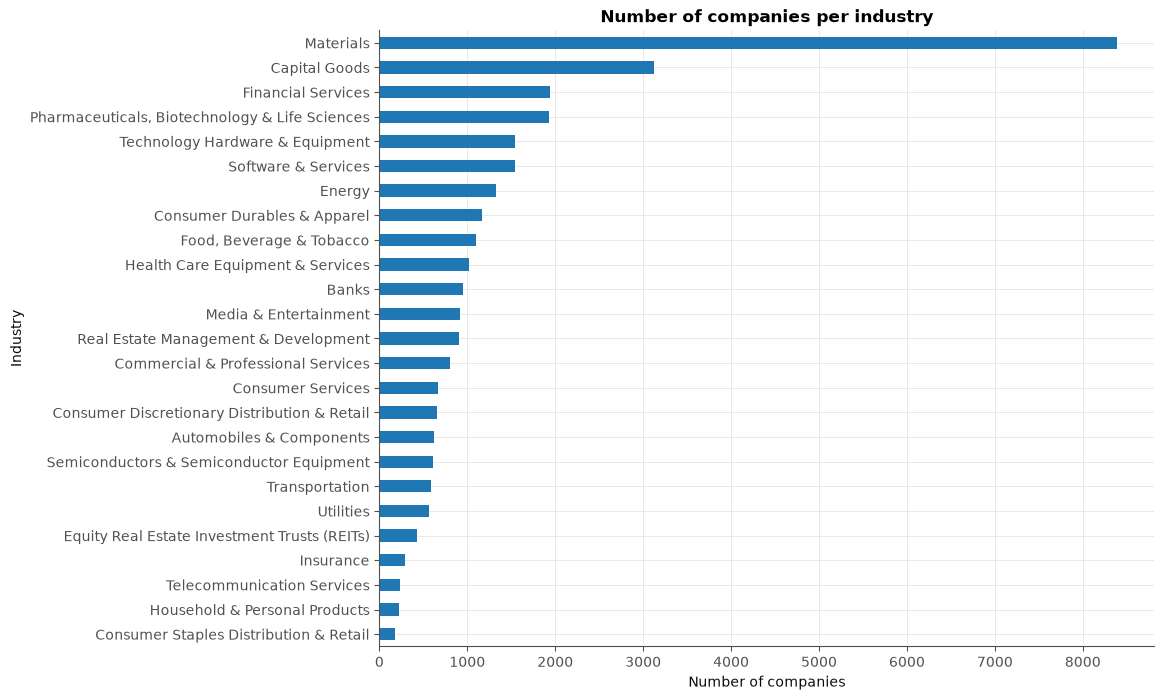

In [20]:
import matplotlib.pyplot as plt

class_counts = df["industry"].value_counts()
print(class_counts)

plt.figure(figsize=(10, 8))
class_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of companies")
plt.ylabel("Industry")
plt.title("Number of companies per industry")
plt.show()

Biggest: Materials with 8,394 companies, 8,394 / 31,706 ≈ 26.5% of all companies, so about 1 in 4 is Materials.

Smallest: Consumer Staples Distribution & Retail (178), then Household & Personal Products (226), Telecommunication Services (230) and Insurance (287). Each of these is below 1% of the data.

How unbalanced? 8,394 / 178 ≈ 47 times bigger. If all 25 industries were the same size, each would have 31,706 / 25 ≈ 1,268 companies. Only 7 industries reach that; 18 of the 25 are below it. So the dataset is strongly imbalanced.

The top 3 (Materials, Capital Goods, Financial Services) together hold 13,457 / 31,706 ≈ 42% of all companies.

The “lazy” model: a model that always says “Materials” would be right 26.5% of the time. That’s our baseline. Any real model has to beat it clearly, otherwise it hasn’t learned anything useful. It’s much higher than random guessing (1/25 = 4%), which shows why plain accuracy can be misleading with imbalanced data.

What imbalance means for us

Big classes: the model sees thousands of examples of Materials, so it will learn them well.
Small classes: for Consumer Staples Retail it only sees about 160 examples, so it will probably do worse there.
Metrics: a model can get high accuracy just by being good at the big classes. That’s why the task also asks for the F1 score, which we’ll look at per industry later.
Template rows: without the 4,463 template rows Materials would have about 3,900 companies. It would still be the biggest class, but much less dominant.

***Step 9: Split into training and validation data***

In [21]:
from sklearn.model_selection import train_test_split

df_train, df_val = train_test_split(df, test_size=0.1, random_state=42)

X_train = X[df.index.get_indexer(df_train.index)]
X_val = X[df.index.get_indexer(df_val.index)]

print(df_train.shape, X_train.shape)
print(df_val.shape, X_val.shape)

(28535, 4) (28535, 768)
(3171, 4) (3171, 768)


Training set: 28,535 companies (90%). Validation set: 3,171 companies (10%). Together that’s 31,706, so no company was lost.

Rows match: df_train and X_train both have 28,535 rows, and df_val and X_val both have 3,171. So features and labels line up.

Why 4 columns and not 3? In Step 7 we added the is_template column. The 4 columns are id, industry, business_description_embedding and is_template. X_train still has 768 columns, because the numbers didn’t change.

Answer to question 2 (small industries). We didn’t stratify the split. Stratifying (stratify=df["industry"]) would force every industry to have exactly the same share in training and validation. Without it the shares can differ a little by chance. For big industries that doesn’t matter. But the smallest one (178 companies) will only have about 18–20 companies in validation, so a single company more or less changes its score by about 5 percentage points. Its score will therefore be noisy. We keep the skeleton’s split anyway, because the instructions use it. We’ll just remember to be careful about drawing conclusions from the smallest industries.

***Step 10: Label encoding (turn industry names into numbers)***

In [22]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(df_train["industry"])

y_train = le.transform(df_train["industry"])
y_val = le.transform(df_val["industry"])

print(le.classes_)
print(y_train[:10])
print(df_train["industry"].values[:3])

missing = set(df_val["industry"]) - set(df_train["industry"])
print("Industries in validation but not in training:", missing)

['Automobiles & Components' 'Banks' 'Capital Goods'
 'Commercial & Professional Services'
 'Consumer Discretionary Distribution & Retail'
 'Consumer Durables & Apparel' 'Consumer Services'
 'Consumer Staples Distribution & Retail' 'Energy'
 'Equity Real Estate Investment Trusts (REITs)' 'Financial Services'
 'Food, Beverage & Tobacco' 'Health Care Equipment & Services'
 'Household & Personal Products' 'Insurance' 'Materials'
 'Media & Entertainment' 'Pharmaceuticals, Biotechnology & Life Sciences'
 'Real Estate Management & Development'
 'Semiconductors & Semiconductor Equipment' 'Software & Services'
 'Technology Hardware & Equipment' 'Telecommunication Services'
 'Transportation' 'Utilities']
[10 21  5 15 12 15 24 17 19 17]
['Financial Services' 'Technology Hardware & Equipment'
 'Consumer Durables & Apparel']
Industries in validation but not in training: set()


le.classes_ lists the 25 industries alphabetically. Each one’s position in the list is its number, counting from 0:

0 = Automobiles & Components
1 = Banks
2 = Capital Goods
…
15 = Materials
…
24 = Utilities

Checking that the encoding matches. The first three labels in y_train are 10, 21, 5:

10 → position 10 in the list is Financial Services ✓
21 → Technology Hardware & Equipment ✓
5 → Consumer Durables & Apparel ✓

These are exactly the three names printed below, so the encoding is correct. You can also see 15 twice in the first 10 labels: that’s Materials, the biggest class, as we’d expect.

set() is Python’s way of printing an empty set. No industry is missing from training, so all 25 can be learned and predicted. ✓

That finishes the skeleton’s “Transforming Data” section. Next is “Visualize the data”: class distribution (done in Step 8) and now PCA.

***Step 11: PCA, shrinking 768 dimensions down to 2***

We can’t plot 768 dimensions. PCA (Principal Component Analysis) finds the directions in which the data spreads out the most, so we can keep the 2 most important ones and plot those.

In [23]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(X_train)

X_train_2d = pca.transform(X_train)

print(X_train_2d.shape)
print(pca.explained_variance_ratio_)
print("together:", pca.explained_variance_ratio_.sum())

(28535, 2)
[0.19296003 0.06101559]
together: 0.25397561864635615


(28535, 2): every training company now has just 2 numbers instead of 768, so we can draw it as a point on a normal x–y plot.

Explained variance:

PC1 keeps 19.3% of the total spread.
PC2 keeps 6.1%.
Together: 25.4%, so about a quarter of the information.

What this means: the 2-D plot shows only a quarter of what’s in the data, and three quarters is lost. So:

If industries look separated in 2-D, they’re definitely different. That’s a strong sign of signal.
If industries overlap in 2-D, that does not prove they overlap in the full 768 dimensions. They may be separated along directions we threw away.

Something suspicious: PC1 (19.3%) is more than 3 times bigger than PC2 (6.1%). One very dominant direction can be a sign of an outlier group. Remember our 4,475 template companies that all sit on (almost) one single point? A big group far from everyone else creates a lot of “spread” in one direction. We’ll see in the plot if that’s what’s happening.

***Step 12: Plot the companies in 2-D, coloured by industry***

With 25 industries, 25 colours would be impossible to tell apart. So we draw all companies in grey and highlight 3 industries that should be very different from each other.

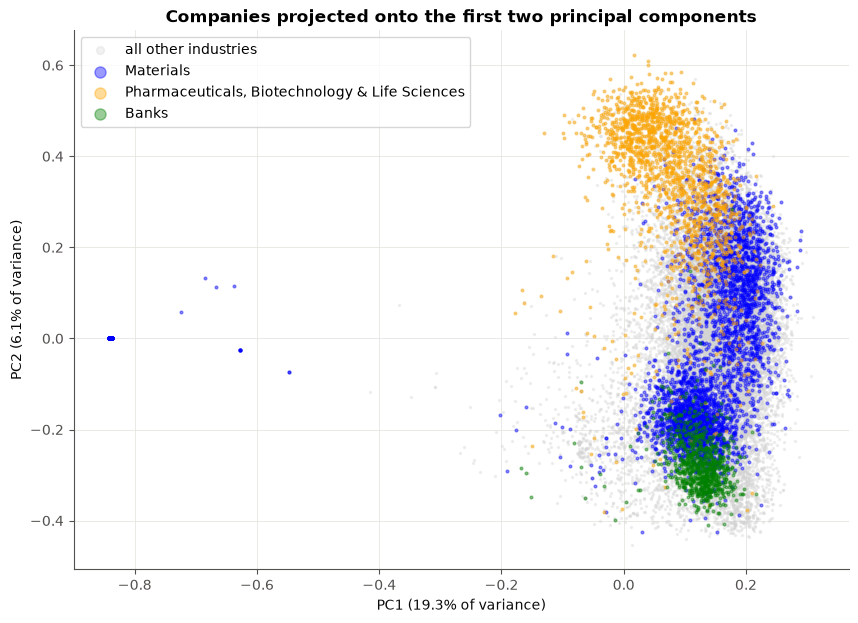

In [ ]:
industries_train = df_train["industry"].values

plt.figure(figsize=(10, 7))
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], s=2, c="lightgrey", alpha=0.3, label="all other industries")

for name, color in [("Materials", "blue"), ("Pharmaceuticals, Biotechnology & Life Sciences", "orange"), ("Banks", "green")]:
    mask = industries_train == name
    plt.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], s=4, c=color, alpha=0.4, label=name)

plt.xlabel("PC1 (19.3% of variance)")
plt.ylabel("PC2 (6.1% of variance)")
plt.title("Companies projected onto the first two principal components")
plt.legend(markerscale=4)
plt.show()

1. The strange point on the far left (PC1 ≈ −0.84)
There’s a dense blue dot far away from everything else. That’s our 4,048 training companies with the template embedding, all on exactly the same spot. The few scattered blue dots nearby are the smaller duplicate groups (116, 19, 9, …).

This explains the suspicious number from Step 11: PC1 is mostly measuring “template vs. real description”. Because thousands of identical points sit far away, PCA uses its most important direction to capture that gap. The cost is that all the real companies get squeezed into the narrow strip on the right (PC1 between about −0.1 and 0.3), where it’s harder to see their structure.

2. The three industries sit in different regions

Pharma/Biotech (orange) is mostly at the top (PC2 ≈ 0.3 to 0.6).
Banks (green) form a compact group at the bottom (PC2 ≈ −0.2 to −0.4).
Materials (blue) spreads over the middle and right, and seems to have two parts: one around PC2 ≈ 0.1 and a dense one around PC2 ≈ −0.2.
The grey (all other industries) fills the space in between.

There is overlap: Pharma blends into Materials around PC2 ≈ 0.2, and Banks touch the lower Materials group. But remember, this plot shows only 25% of the information, so some of this overlap may disappear in the full 768 dimensions.

3. Is there signal? Yes. Even with 2 out of 768 dimensions, companies of the same industry clearly gather in the same region. If the embeddings had no industry information, all three colours would be mixed randomly over the whole cloud.

Step 13: PCA again, without the template rows

To see the real structure better, we fit a PCA on the real descriptions only. This is only for the picture: the models will still use all the data.

[0.07509208 0.05616432]


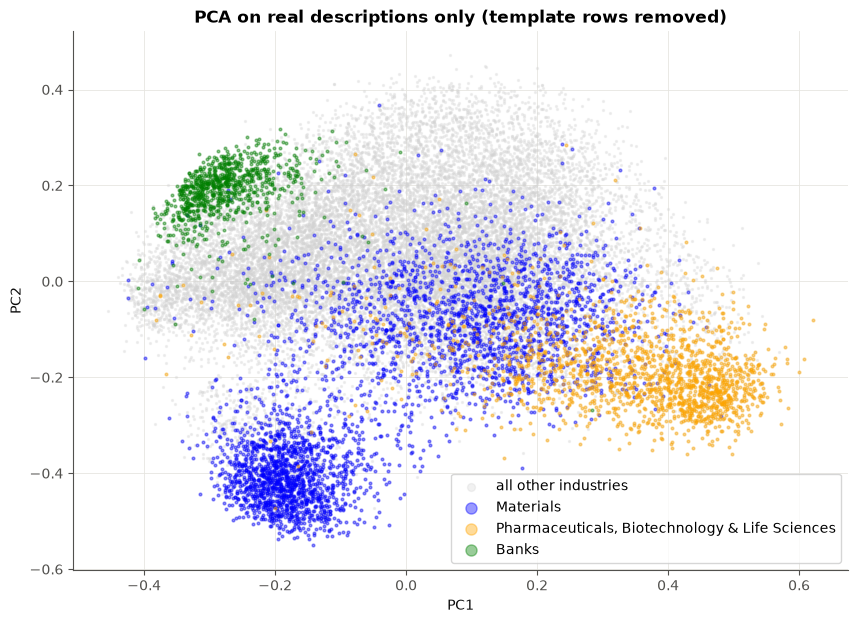

In [25]:
real = ~df_train["is_template"].values

pca_real = PCA(n_components=2)
X_real_2d = pca_real.fit_transform(X_train[real])
industries_real = industries_train[real]

print(pca_real.explained_variance_ratio_)

plt.figure(figsize=(10, 7))
plt.scatter(X_real_2d[:, 0], X_real_2d[:, 1], s=2, c="lightgrey", alpha=0.3, label="all other industries")

for name, color in [("Materials", "blue"), ("Pharmaceuticals, Biotechnology & Life Sciences", "orange"), ("Banks", "green")]:
    mask = industries_real == name
    plt.scatter(X_real_2d[mask, 0], X_real_2d[mask, 1], s=4, c=color, alpha=0.4, label=name)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA on real descriptions only (template rows removed)")
plt.legend(markerscale=4)
plt.show()

What the plot shows

1. PC1 is no longer dominant. It drops from 19.3% to about 7.5%, close to PC2’s 5.6%. This confirms that the big PC1 in the first PCA was mainly caused by the template rows. Now the two main directions describe the real differences between descriptions.

2. The three industries are much better separated

Banks (green) form a tight, compact cluster at the top left. Bank descriptions are very similar to each other (“deposits, loans, branches…”) and different from everything else.
Pharma/Biotech (orange) form a clear cluster on the far right.
Materials (blue) is in the middle and bottom.

Their centres are far apart. That’s a very good sign for classification.

3. Materials has two groups

A dense, compact cluster at the bottom left (around PC1 ≈ −0.2, PC2 ≈ −0.4). This is probably mining and mineral exploration companies. There are many of them (e.g. small gold/lithium explorers in Canada and Australia), and their descriptions sound almost identical.
A wider cloud in the middle, probably chemicals, steel, paper and packaging companies, which are more varied.

So one industry can consist of several distinct groups. That’s useful to know: k-NN, which looks at nearby companies, handles such multi-part industries naturally. A linear model like logistic regression might find it harder, although in 768 dimensions it may still manage.

4. Overlap remains in the centre. The grey cloud (the other 22 industries) is mixed in the middle, and Materials touches Pharma around PC1 ≈ 0.25 (perhaps chemical companies that sound like pharma). With only about 13% of the variance shown, this is expected.

Conclusion for the skeleton question: “Is there signal in the data that allows industry classification?” Yes, clearly. Even in a strongly compressed 2-D view, companies of the same industry gather in their own regions. Some industries (Banks, Pharma, mining-type Materials) are very distinct; others overlap in the centre and will probably be harder to classify.

***Step 14: One small plot per industry***

The task says “colour based on classes”. Instead of 25 colours in one plot, we draw 25 small plots, one per industry, each with that industry highlighted.

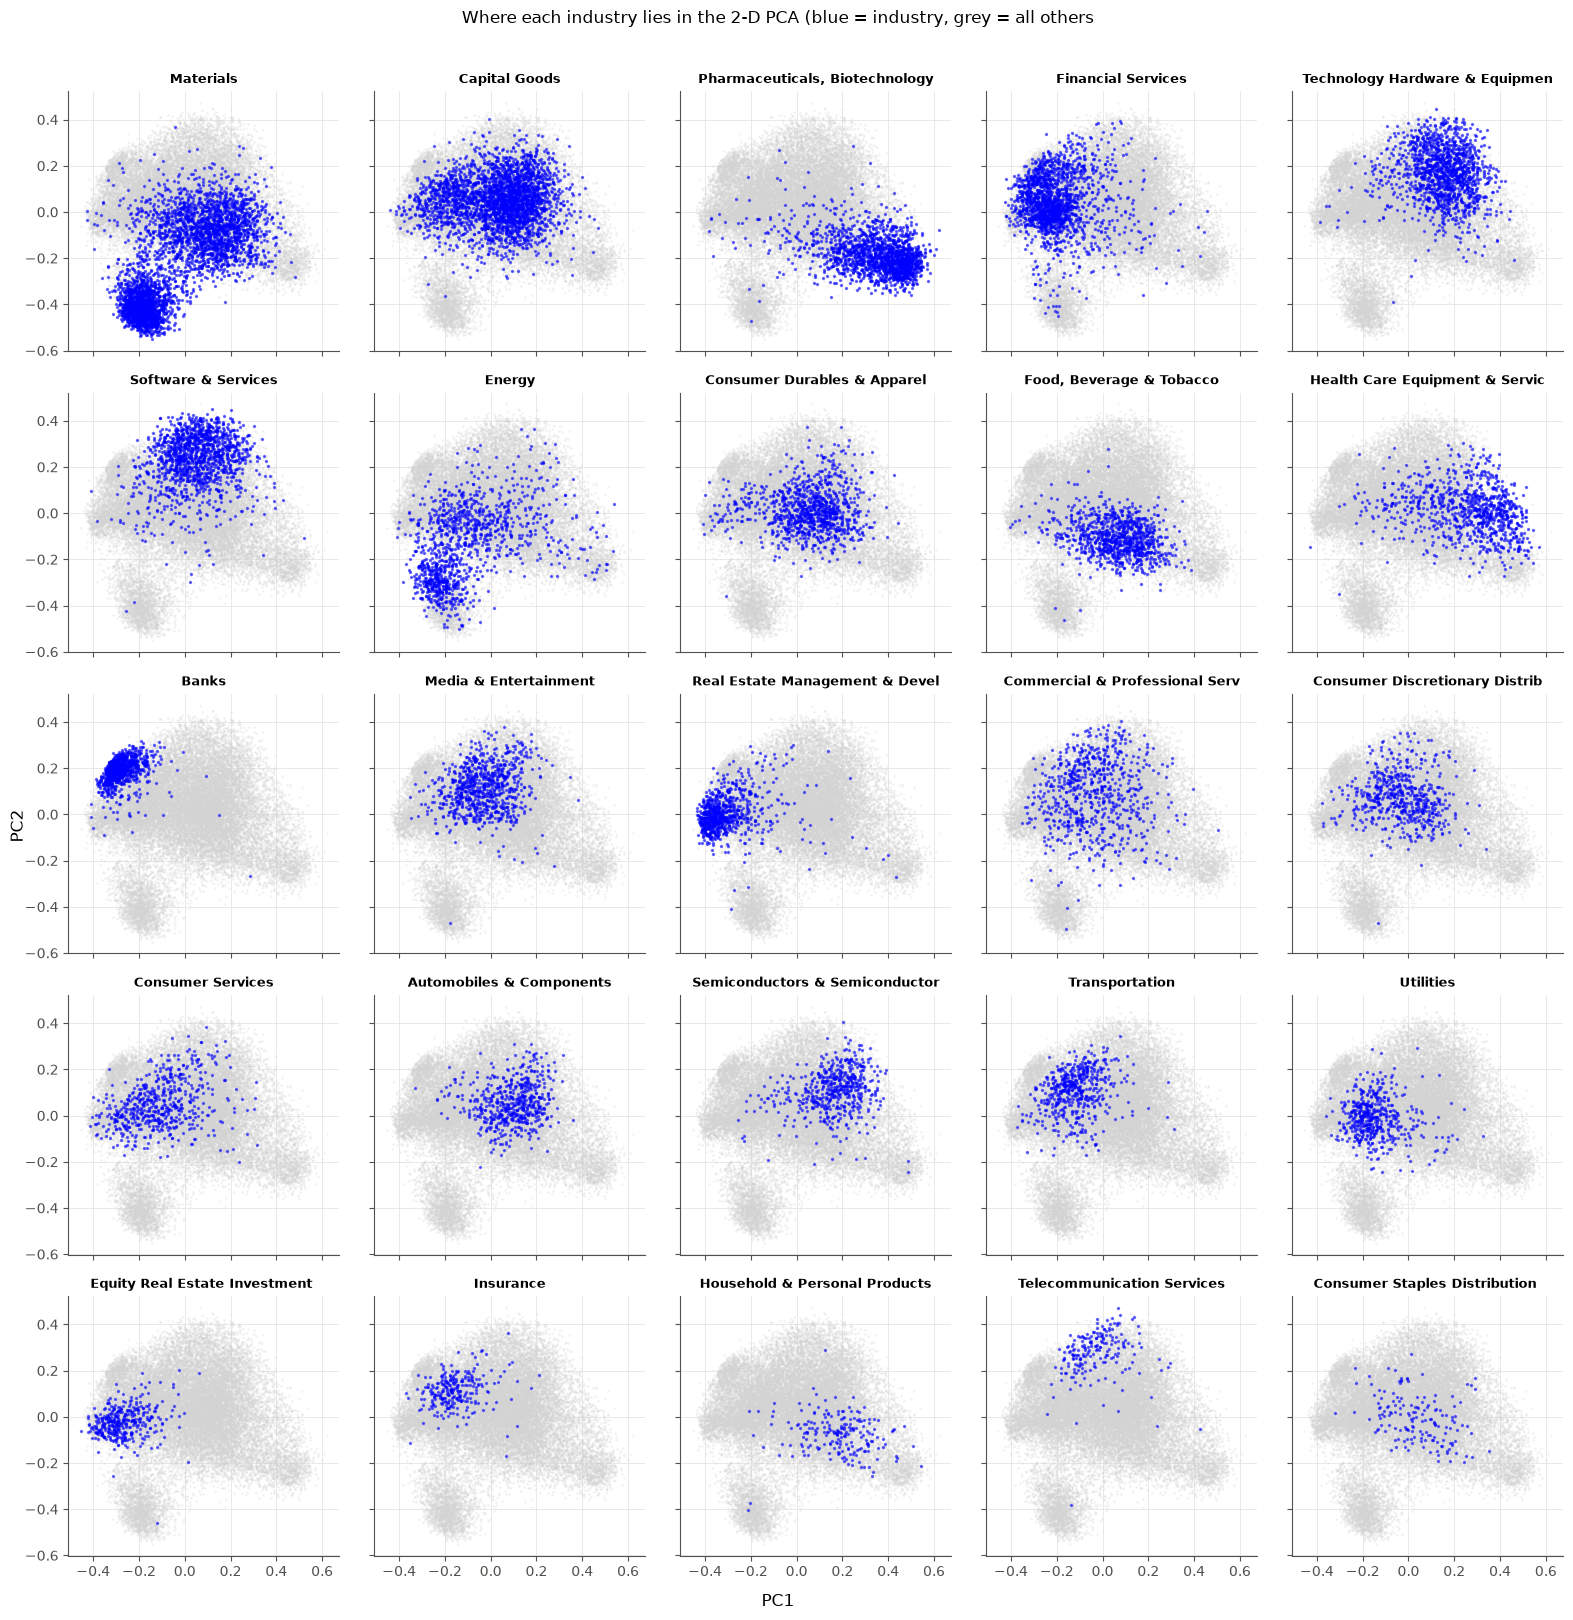

In [29]:
industry_names = df_train["industry"].value_counts().index

fig, axes = plt.subplots(5, 5, figsize=(16, 16), sharex=True, sharey=True)

for ax, name in zip(axes.flat, industry_names):
    mask = industries_real == name
    ax.scatter(X_real_2d[:, 0], X_real_2d[:, 1], s=1, c="lightgrey", alpha=0.2)
    ax.scatter(X_real_2d[mask, 0], X_real_2d[mask, 1], s=2, c="blue", alpha=0.5)
    ax.set_title(name[:30], fontsize=9)

fig.supxlabel("PC1")
fig.supylabel("PC2")
fig.suptitle("Where each industry lies in the 2-D PCA (blue = industry, grey = all others",y=1.01)
plt.tight_layout()
plt.show()

What the plot shows

1. Compact, separate groups (should be easy to classify)

Banks: a very tight cluster at the top left, almost nothing elsewhere.
Real Estate Management and Equity REITs: compact, on the far left.
Pharma/Biotech: a clear cluster on the far right.
Materials: the dense mining cluster at the bottom, plus a wider middle group.
Software & Services (top centre), Technology Hardware (top right) and Food, Beverage & Tobacco (centre bottom) also have a clear centre.

2. Spread over the centre (probably hard)

Capital Goods: huge and wide, covering most of the middle. It’s a broad “makes industrial things” category.
Commercial & Professional Services, Consumer Services, Consumer Discretionary Retail, Consumer Durables & Apparel, Media & Entertainment: all scattered over the middle with no clear centre.
Consumer Staples Distribution (the smallest class): few points, spread out, sitting where Food & Beverage is. A supermarket’s description talks a lot about food, so it will be confused with food producers.
Energy has two parts: one sits right on top of the Materials mining cluster (oil and gas exploration companies sound like mining explorers), the other is spread out.

3. Related industries sit close together

Finance group (left): Banks, Financial Services, Insurance, Real Estate and REITs are neighbours, but each has its own spot. Real Estate and REITs overlap heavily, so they’ll probably be confused.
Tech group (top/right): Software, Technology Hardware, Semiconductors and Telecom all sit in the upper right and overlap, so expect confusion between them.
Health group (right): Pharma, Health Care Equipment and Household & Personal Products are all on the right side.

The embedding has captured real economic relationships: industries that are similar in the real world are close together. 

Prediction for the models: distinct industries (Banks, Pharma, Real Estate, Materials) should be classified well. The central ones (Capital Goods, Commercial Services, the consumer industries) and the smallest ones will be harder. We’ll check this prediction later with the confusion matrix.


***Step 15: First model, logistic regression***

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

pred_lr = lr.predict(X_val)

print("Accuracy:   ", accuracy_score(y_val, pred_lr))
print("F1 weighted:", f1_score(y_val, pred_lr, average="weighted"))
print("F1 macro:   ", f1_score(y_val, pred_lr, average="macro"))

Accuracy:    0.771996215704825
F1 weighted: 0.7662843100318403
F1 macro:    0.695451893252825


What the result shows

Accuracy 0.772: the model gets 77.2% of validation companies right, about 3 out of 4.

Our “always Materials” baseline gets 26.5% (on this exact validation set it’s 24.9%, because Materials is slightly less common there).
So the model is about 3 times better than the lazy guess, and far better than random guessing (4%).
The model has really learned something from the embeddings.

Remember the template rows though: about 13% of the validation companies are placeholder Materials rows that the model gets right “for free”. On real descriptions alone, accuracy would be a few points lower (around 74%). We can check that later.

F1 weighted 0.766: close to the accuracy. That’s expected, because weighted F1 is dominated by the large industries, just as accuracy is.

F1 macro 0.695: about 7 points lower than weighted F1. Macro F1 gives every industry equal weight, so this gap tells us that small industries are classified worse on average than big ones. It matches our prediction from the PCA plots: Consumer Staples Retail, Household Products and Commercial Services looked hard. We’ll check per industry later to see whether it’s really about size, or about how distinct an industry’s descriptions are.

Is this good? For 25 classes, where several overlap in meaning (Real Estate vs REITs, Semiconductors vs Tech Hardware), 77% is a solid start.

***Step 16: Second model, k-nearest neighbours (k-NN)***

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

pred_knn = knn.predict(X_val)

print("Accuracy:   ", accuracy_score(y_val, pred_knn))
print("F1 weighted:", f1_score(y_val, pred_knn, average="weighted"))
print("F1 macro:   ", f1_score(y_val, pred_knn, average="macro"))

Accuracy:    0.7530747398297067
F1 weighted: 0.749546001399183
F1 macro:    0.6800234108942722


***A table to make comparison***

In [33]:
majority = np.bincount(y_train).argmax()
pred_base = np.full(len(y_val), majority)

def get_scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1 weighted": f1_score(y_true, y_pred, average="weighted"),
        "F1 macro": f1_score(y_true, y_pred, average="macro"),
    }

results = pd.DataFrame({
    "Baseline (always Materials)": get_scores(y_val, pred_base),
    "Logistic regression": get_scores(y_val, pred_lr),
    "k-NN (k = 5)": get_scores(y_val, pred_knn),
}).T

results.round(3)

,Accuracy,F1 weighted,F1 macro
Baseline (always Materials),0.249,0.099,0.016
Logistic regression,0.772,0.766,0.695
k-NN (k = 5),0.753,0.750,0.680


k-NN is about 2 points worse than logistic regression on all three metrics. It’s still about 3 times better than the baseline, so it has also learned a lot from the embeddings.

Gap between weighted and macro F1: 0.750 − 0.680 = 0.07 for k-NN, about the same as for logistic regression (0.071). Both models are weaker on small industries to a similar degree.

Is this a fair comparison? Not quite yet. We used the default settings for both models (k = 5 for k-NN, the default penalty for logistic regression), and either one might do better with different settings. These settings are called hyperparameters: choices we make before training, as opposed to the weights the model learns itself.

***Step 17: Choose k properly***

Important rule: we must not choose k by looking at the validation score. If we tried 10 values of k and kept the best validation score, that score would be too optimistic: we’d have “tuned to” the validation set, and it would no longer act like unseen data.

Solution: split the training data once more. Train on 85% of it and test the k values on the other 15% (a tuning set). The validation set stays untouched for the final comparison.

In [32]:
X_fit, X_tune, y_fit, y_tune = train_test_split(X_train, y_train, test_size=0.15, random_state=42)

for k in [1, 5, 10, 15, 25, 50]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_fit, y_fit)
    pred = model.predict(X_tune)
    print("k =", k, " F1 weighted =", round(f1_score(y_tune, pred, average="weighted"), 4))

k = 1  F1 weighted = 0.7126
k = 5  F1 weighted = 0.751
k = 10  F1 weighted = 0.7632
k = 15  F1 weighted = 0.7631
k = 25  F1 weighted = 0.7549
k = 50  F1 weighted = 0.7489


***Step 18: Tune logistic regression the way***

Logistic regression also has a hyperparameter: C, which controls the penalty from Step 15.

In [34]:
for C in [0.1, 1, 10]:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_fit, y_fit)
    pred = model.predict(X_tune)
    print("C =", C, " F1 weighted =", round(f1_score(y_tune, pred, average="weighted"), 4))

C = 0.1  F1 weighted = 0.7151
C = 1  F1 weighted = 0.7652
C = 10  F1 weighted = 0.7696


C = 0.1 is too restrictive. The strong penalty forces all weights to stay small, so the model can’t express the differences between 25 industries well. This is underfitting: the model is too simple.

C = 10 is best, but only slightly better than C = 1 (+0.004). The improvement is getting smaller, so we’re near the top. Trying C = 100 would probably give about the same result, while training would take longer.

Answer to question 2: we have 28,000 companies and 768 features, about 37 examples per feature, and with 25 classes the model has 25 × 769 ≈ 19,000 weights to learn. That’s enough data that the model doesn’t easily memorise noise, so a weak penalty (large C) works best. With only, say, 500 training companies, a stronger penalty (smaller C) would probably win.

Choice: C = 10.

***Step 19: Train both models with the best settings and compare on the validation set***

Now we train both final models on the full training set (not just the 85% part) and evaluate them once on the untouched validation set.

In [35]:
lr = LogisticRegression(C=10, max_iter=1000)
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_val)

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_val)

results = pd.DataFrame({
    "Baseline (always Materials)": get_scores(y_val, pred_base),
    "Logistic regression (C = 10)": get_scores(y_val, pred_lr),
    "k-NN (k = 10)": get_scores(y_val, pred_knn),
}).T

results.round(3)

,Accuracy,F1 weighted,F1 macro
Baseline (always Materials),0.249,0.099,0.016
Logistic regression (C = 10),0.777,0.774,0.713
k-NN (k = 10),0.772,0.767,0.695


Tuning helped both models.

Logistic regression: +0.5 points accuracy and +1.8 points macro F1. The weaker penalty helps most for the small industries.
k-NN: +1.9 points accuracy, a bigger gain than for logistic regression. k = 5 was too small and noisy.

Which is better? Logistic regression is slightly ahead on every metric: +0.5 points accuracy, +0.7 weighted F1 and +1.8 macro F1. The difference is small. With 3,171 validation companies, 0.5 points is only about 16 companies. It could be real or just luck; we’ll test this properly later with a statistical test (McNemar’s test).

Interpretation for the skeleton

Both models are about 3× better than the baseline, so the embeddings carry strong industry information.
Macro F1 is about 6–7 points below weighted F1 for both, so small industries are harder on average.
About 13% of validation companies are template rows that are right “for free”, so on real descriptions accuracy is around 74%.
For 25 partly overlapping industries, this is a good result.

***Step 20: Performance per industry***

The averages hide a lot. Let’s look at each industry separately.

In [36]:
from sklearn.metrics import classification_report

print(classification_report(y_val, pred_lr, target_names=le.classes_, digits=2))

                                                precision    recall  f1-score   support

                      Automobiles & Components       0.76      0.70      0.73        53
                                         Banks       0.99      0.95      0.97        74
                                 Capital Goods       0.66      0.74      0.70       322
            Commercial & Professional Services       0.61      0.42      0.50        78
  Consumer Discretionary Distribution & Retail       0.70      0.63      0.66        67
                   Consumer Durables & Apparel       0.70      0.61      0.66       127
                             Consumer Services       0.70      0.72      0.71        81
        Consumer Staples Distribution & Retail       0.29      0.20      0.24        20
                                        Energy       0.81      0.59      0.68       152
  Equity Real Estate Investment Trusts (REITs)       0.76      0.82      0.79        45
                            Fin

Highest F1 (easy industries)

Industry	F1	Support
Banks	    0.97	74
Materials	0.93	790
Food, Beverage & Tobacco	0.84	138
Pharma/Biotech	0.82	183
Transportation	0.82	57

These match the PCA plots: Banks formed the tightest cluster, and Pharma and Food had clear centres. Materials is helped by its compact mining cluster and the “free” template rows.

Notice that Banks is a small industry (only about 3% of the data) but has the best score of all. So being small doesn’t automatically mean being hard.

Lowest F1 (hard industries)

Industry	F1	Support
Consumer Staples Distribution & Retail	0.24	20
Commercial & Professional Services	0.50	78
Household & Personal Products	0.53	20
Technology Hardware & Equipment	0.62	157
Consumer Durables, Consumer Discretionary Retail, Software	0.66	67–153

It’s a mix of both reasons:

Small and overlapping: Consumer Staples Retail and Household Products, both with only about 200 training examples, sitting in the middle of other industries in the PCA plot.
Not small, but spread out or overlapping: Commercial & Professional Services (scattered over the whole centre), and Technology Hardware and Software (overlapping each other in the tech region).

Precision vs recall (question 3)

Energy: precision 0.81, recall 0.59. When the model says “Energy” it’s usually right (81%), but it misses 41% of real energy companies. In the PCA plot part of Energy sat on top of the Materials mining cluster, so many oil and gas explorers are probably being called “Materials”.
Commercial & Professional Services: precision 0.61, recall 0.42. The model finds fewer than half of them. Their descriptions are too general (“consulting, staffing, security services…”) and get assigned to other industries.
Capital Goods: precision 0.66, recall 0.74. The opposite pattern: recall is higher than precision, so the model says “Capital Goods” too often. It’s a broad category that catches companies from other industries.

Support warning: Consumer Staples Retail and Household Products have only 20 validation companies each. One company more or less right changes their F1 by about 5 points, so their scores are uncertain.

***Step 21: Do the errors depend on class size?***

The skeleton asks: “Do the errors correlate with how well classes are represented?” Let’s test it with a plot and a number.

Spearman correlation: 0.17  p-value: 0.406


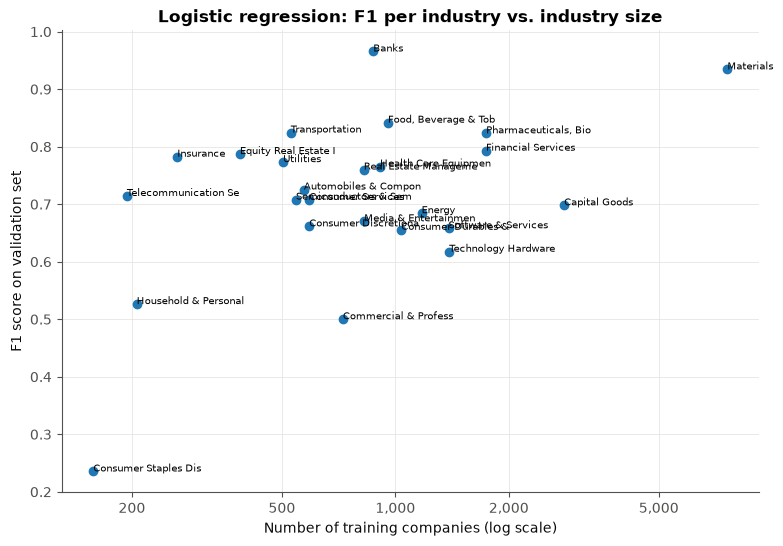

In [ ]:
from scipy.stats import spearmanr

f1_per_class = f1_score(y_val, pred_lr, average=None)
train_size = np.bincount(y_train)

rho, p = spearmanr(train_size, f1_per_class)
print("Spearman correlation:", round(rho, 2), " p-value:", round(p, 3))

plt.figure(figsize=(9, 6))
plt.scatter(train_size, f1_per_class)
for i, name in enumerate(le.classes_):
    plt.annotate(name[:20], (train_size[i], f1_per_class[i]), fontsize=7)
plt.xscale("log")
plt.xlabel("Number of training companies (log scale)")
plt.ylabel("F1 score on validation set")
plt.title("Logistic regression: F1 per industry vs. industry size")
plt.xticks([200, 500, 1000, 2000, 5000], ["200", "500", "1,000", "2,000", "5,000"])
plt.minorticks_off()
plt.show()

***Step 22: Confusion matrix (which industries get mixed up?)***

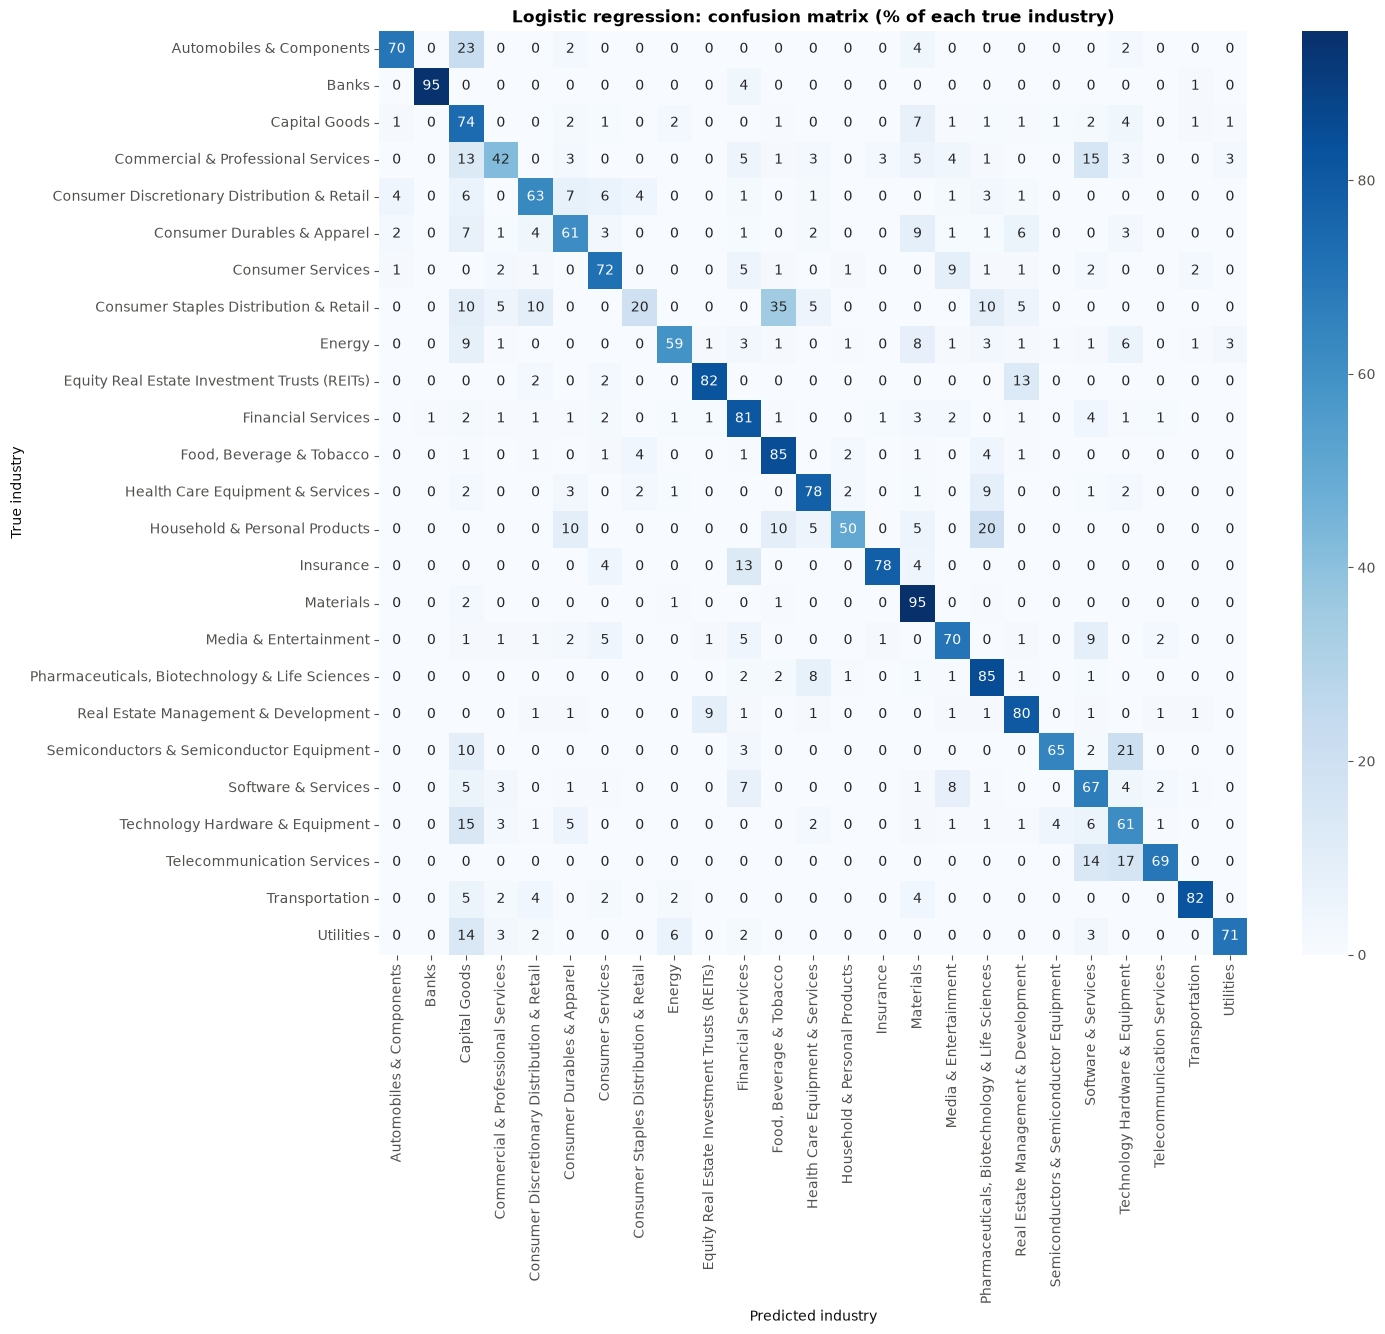

In [41]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_val, pred_lr, normalize="true") * 100

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted industry")
plt.ylabel("True industry")
plt.title("Logistic regression: confusion matrix (% of each true industry)")
plt.show()

What the confusion matrix shows

The diagonal (correct predictions) is dark for Banks (95), Materials (95), Food & Beverage (85), Pharma (85), REITs (82), Transportation (82), Financial Services (81) and Real Estate (80). These are the same easy industries as in the classification report; the diagonal is exactly the recall.

1. The biggest mix-ups (off-diagonal)

| True industry | → Predicted as | % | Makes sense? |
|---|---|---|---|
| Consumer Staples Retail | Food, Beverage & Tobacco | 35 | Supermarkets sell food, so their descriptions are full of food words |
| Automobiles & Components | Capital Goods | 23 | Car parts makers sound like machinery/industrial makers |
| Semiconductors | Technology Hardware | 21 | Chips are hardware, and the two sectors are closely related |
| Household & Personal Products | Pharma/Biotech | 20 | Cosmetics and personal care sound like health products |
| Telecom | Tech Hardware / Software | 17 / 14 | Telecom firms describe networks, devices and digital services |
| Commercial & Prof. Services | Software & Services | 15 | "Services" for businesses: IT services, consulting… |
| Technology Hardware | Capital Goods | 15 | Electronic equipment vs. industrial equipment |
| Utilities | Capital Goods | 14 | Power generation and equipment |
| REITs | Real Estate Management | 13 | Both own and manage property; the difference is mostly a legal/tax structure |
| Insurance | Financial Services | 13 | Both are finance |

*% = share of companies of the true industry that were predicted as the other industry (row-normalised confusion matrix).*

2. Do they make sense? Yes, almost all of them. The model confuses industries that are genuinely similar in the real world, mostly within the same broader sector:

Finance: Insurance ↔ Financial Services, REITs ↔ Real Estate
Tech: Semiconductors ↔ Tech Hardware ↔ Telecom ↔ Software
Health: Household Products ↔ Pharma; Pharma ↔ Health Care Equipment (8%)
Consumer: Consumer Staples Retail ↔ Food

These are not “stupid” errors. Many sit on blurry industry borders where even a human analyst might hesitate. They also match what we saw in the PCA plots: these pairs were neighbours there.

3. The column that “collects” mistakes: Capital Goods. Look down the Capital Goods column. It receives errors from many rows: Automobiles 23%, Tech Hardware 15%, Utilities 14%, Commercial Services 13%, Consumer Staples 10%, Semiconductors 10%, Energy 9%, Consumer Durables 7%…

Capital Goods is large and broad (machinery, electrical equipment, construction, engineering). Any description mentioning manufacturing, equipment or engineering gets pulled towards it. It’s the model’s “default guess” when unsure about an industrial-sounding company. That’s why Capital Goods has higher recall (0.74) than precision (0.66): it’s predicted too often.

Smaller observations

Energy → Materials (8%) and Capital Goods (9%): as expected from the PCA, oil and gas explorers sound like mining explorers.
Commercial & Professional Services spreads its errors over 10+ different industries: it has no clear identity in the embedding space.

***Step 23: The same matrix for k-NN***

The skeleton asks for a confusion matrix for both models. 

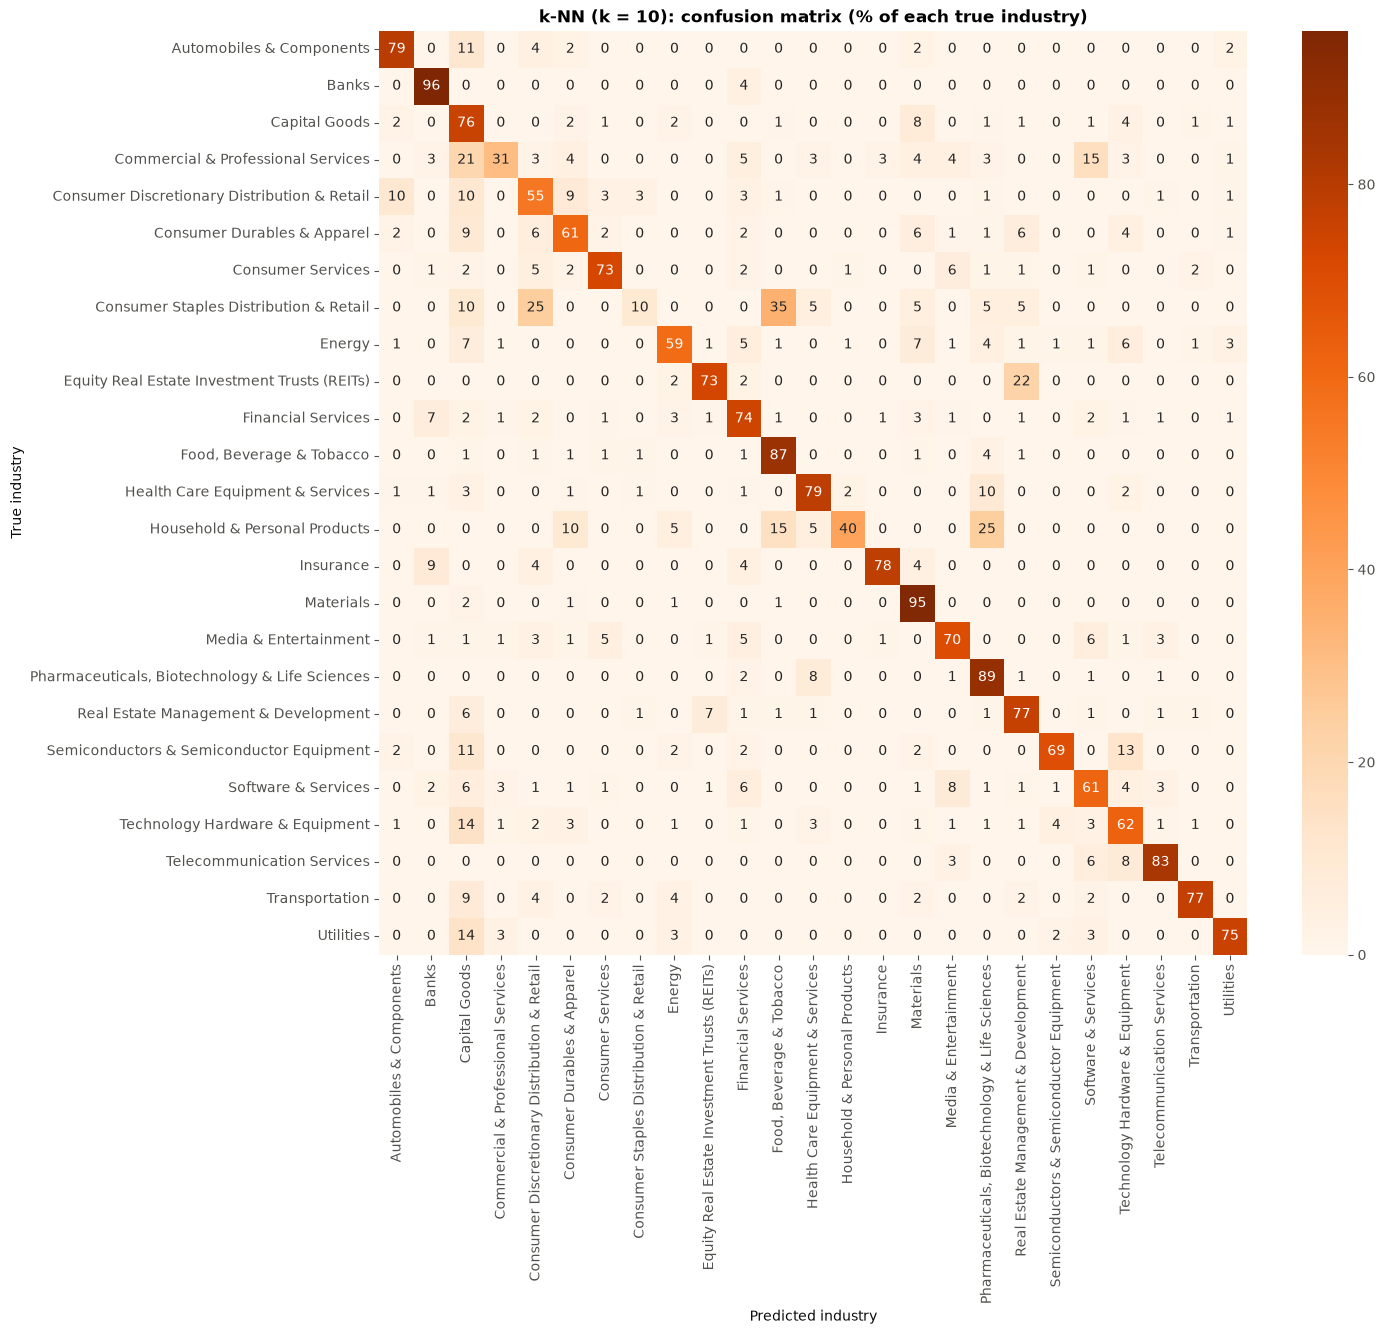

In [42]:
cm_knn = confusion_matrix(y_val, pred_knn, normalize="true") * 100

plt.figure(figsize=(14, 12))
sns.heatmap(cm_knn, annot=True, fmt=".0f", cmap="Oranges",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted industry")
plt.ylabel("True industry")
plt.title("k-NN (k = 10): confusion matrix (% of each true industry)")
plt.show()

What the k-NN confusion matrix shows

1. Mostly the same mistakes as logistic regression. The same industry pairs appear:

Consumer Staples Retail → Food (35%, identical)
REITs → Real Estate (22%, even more than LR’s 13%)
Household Products → Pharma (25%)
Commercial Services → Capital Goods (21%) and Software (15%)
Semiconductors → Tech Hardware (13%)

2. Smallest industries: k-NN is worse

Capital Goods is again the column that collects errors from many industries. This makes sense: both models use the same embeddings, so whatever looks similar in the embedding space confuses both.

The reason is how k-NN votes. A supermarket company has only about 160 other supermarkets in training, but over 900 food producers that sound similar. Among its 10 nearest neighbours there are usually more food companies than supermarkets, so “Food” wins the vote. Logistic regression learns a separate weight vector for each industry, so it can pick up the small differences even with few examples.

3. The Banks column: yes, k-NN predicts “Banks” too often

Financial Services → Banks: 7% (LR: 1%)
Insurance → Banks: 9% (LR: 0%)
Commercial Services → Banks: 3%

Banks form a very dense cluster, so finance companies near its edge often have several banks among their 10 neighbours. That’s why k-NN’s precision for Banks is lower (about 0.76 vs 0.99 for LR), even though its recall is about the same (96%).

### Logistic regression vs. k-NN: recall per industry (where they differ most)

| Industry | LR recall (%) | k-NN recall (%) | Better model | Why |
|---|---|---|---|---|
| Consumer Staples Retail | 20 | 10 | LR | Few examples; food producers outvote supermarkets among the neighbours |
| Household & Personal Products | 50 | 40 | LR | Small class, neighbours are often Pharma |
| Commercial & Prof. Services | 42 | 31 | LR | Spread out, no clear neighbourhood |
| REITs | 82 | 73 | LR | Neighbours often Real Estate Management |
| Telecommunication Services | 69 | 83 | k-NN | Compact sub-groups, similarity works well |
| Automobiles & Components | 70 | 79 | k-NN | Fewer pulled into Capital Goods (11 % vs 23 %) |
| Pharma/Biotech | 85 | 89 | k-NN | Very dense cluster |

**Banks:** both find ~95 % of banks, but k-NN also calls 7 % of Financial Services and 9 % of Insurance "Banks" → lower precision for k-NN.

***Step 24: Do both models misclassify the same companies***


In [43]:
lr_right = pred_lr == y_val
knn_right = pred_knn == y_val

print("both right:        ", np.sum(lr_right & knn_right))
print("only LR right:     ", np.sum(lr_right & ~knn_right))
print("only k-NN right:   ", np.sum(~lr_right & knn_right))
print("both wrong:        ", np.sum(~lr_right & ~knn_right))

both_wrong = ~lr_right & ~knn_right
same_wrong = np.sum(pred_lr[both_wrong] == pred_knn[both_wrong])
print("both wrong AND same wrong answer:", same_wrong)

both right:         2256
only LR right:      209
only k-NN right:    191
both wrong:         515
both wrong AND same wrong answer: 415


### Do both models misclassify the same companies?

|  | k-NN right | k-NN wrong |
|---|---|---|
| **LR right** | 2,256 | 209 |
| **LR wrong** | 191 | 515 |

- 73 % of LR's errors are also made by k-NN; in 81 % of these shared errors both predict the **same wrong industry** → these companies look like another industry in embedding space.
- At least one model is right for 83.8 % of companies (vs 77.7 % for LR alone) → combining models could help.
- When both models agree they are right 84.5 % of the time; when they disagree each is right only ~40 % → agreement is a useful confidence signal.

1. Most mistakes are shared

LR makes 191 + 515 = 706 mistakes. k-NN makes the same mistake on 515 of them, which is 73%.
k-NN makes 209 + 515 = 724 mistakes, and 71% of them are also LR mistakes.

2. Both wrong, with the same wrong answer: 415 of the 515 shared mistakes, which is 81%. In most cases where both fail, they agree on the same wrong industry. This suggests that these companies genuinely look like another industry in the embedding space, for example a supermarket whose description is all about food, or a REIT that reads like a property developer. Possible reasons:

the description is ambiguous, or the company really does business in two industries;
borderline cases like the ones in the confusion matrix (Real Estate ↔ REITs, Semiconductors ↔ Tech Hardware);
maybe a few wrong labels in the data.

No model using these same embeddings will easily fix those, since the information to tell them apart may simply not be in the description.

3. At least one model right: 2,256 + 209 + 191 = 2,656 companies, or 83.8%. Compare that with LR alone at 77.7%. If we could always pick the right model for each company, we’d gain about 6 points. That’s an upper limit (we can’t know in advance which model is right), but it shows that combining the models could help, which is the idea behind the optional ensemble part.

4. When the two models agree, they’re usually right

Both predict the same industry for 2,256 (both right) + 415 (same wrong answer) = 2,671 companies, which is 84% of the time.
Of those, 2,256 / 2,671 = 84.5% are correct.
When they disagree (500 companies), each model is right only about 40% of the time (209/500 for LR, 191/500 for k-NN).

So agreement between the models is a strong signal of confidence. This will be very useful for the optional part.

***Step 25: Is LR really better? McNemar’s test***

LR is right on 209 companies where k-NN is wrong, and k-NN is right on 191 where LR is wrong. Is a difference of 18 companies real, or just luck?


In [ ]:
from scipy.stats import binomtest

b = np.sum(lr_right & ~knn_right)
c = np.sum(~lr_right & knn_right)

result = binomtest(b, b + c, 0.5)
print("b =", b, " c =", c)
print("p-value:", round(result.pvalue, 3))

b = 209  c = 191
p-value: 0.395


p = 0.395, which is far above 0.05.

If both models were truly equally good, a split as uneven as 209 vs 191 (or more uneven) would happen by chance about 40% of the time. That’s very common, like getting 209 heads in 400 coin flips. So we cannot reject $H_0$.

Conclusion: LR’s small advantage (0.5 points accuracy, 18 more correct companies) is not statistically significant. On this data the two models perform equally well overall.

So why might we still prefer logistic regression in practice?

It’s clearly better on the smallest industries (Consumer Staples Retail, Household Products) and has much better precision for Banks. Its higher macro F1 (0.713 vs 0.695) reflects that.
Predicting is fast, because it’s just a formula. k-NN must compare each new company with all 28,535 training companies.
It gives probabilities that are reasonably meaningful, which we’ll need for the optional confidence task.

k-NN is better for a few industries made of tight sub-groups (Telecom, Automobiles), so the models complement each other.

## Summary

**Data.** 31,706 companies, 25 industries, one 768-dimensional embedding per company (all vectors have length 1). No missing values. 14 % of companies (4,475) share a placeholder ("template") embedding; almost all are Materials. We kept them but note they are classified correctly "for free".

**Class distribution.** Strongly imbalanced: Materials = 26.5 % of companies, the smallest industry (Consumer Staples Distribution & Retail) only 0.6 % — 47× smaller. Always predicting Materials gives 24.9 % accuracy (baseline).

**PCA.** Two components keep only ~25 % of the variance (and PC1 was dominated by the template rows). On real descriptions, industries such as Banks, Real Estate, Pharma and mining-type Materials form clearly separate regions; related industries sit next to each other. → There is clear signal for industry classification.

**Models (validation set).**

| Model | Accuracy | F1 weighted | F1 macro |
|---|---|---|---|
| Baseline (always Materials) | 0.249 | 0.099 | 0.016 |
| Logistic regression (C = 10) | 0.777 | 0.774 | 0.713 |
| k-NN (k = 10) | 0.772 | 0.767 | 0.695 |

Hyperparameters (C, k) were chosen on a separate tuning split of the training data, not on the validation set.

**Errors vs. class size.** No significant correlation (Spearman ρ = 0.17, p = 0.41). How distinctive an industry's descriptions are matters more than its size (e.g. Banks: small but F1 = 0.97; Capital Goods: large but F1 = 0.70). Only the very smallest, overlapping industries clearly suffer.

**Confusions.** Mostly between economically similar industries: Consumer Staples Retail → Food, Semiconductors → Tech Hardware, REITs ↔ Real Estate, Insurance → Financial Services, Household Products → Pharma. Capital Goods attracts many errors from industrial-sounding companies.

**Same errors?** Mostly yes: 73 % of LR's errors are also made by k-NN, usually with the same wrong label. McNemar's test (p = 0.395) shows the difference between the models is not significant. At least one model is right for 83.8 % of companies, and when both agree they are right 84.5 % of the time → a good basis for an ensemble and a confidence score.